# Trabalho 2 — Assistente de perguntas e respostas sobre marcas de automóveis (RAG)

**Disciplina:** Tópicos em Computação 2 · **Base:** corpus de marcas de carros do Trabalho 1 (Wikipédia em português)

**Pergunta de pesquisa.** O Trabalho 1 mostrou que o agrupamento (K-Means sobre TF-IDF) *não* recupera o "perfil de marca" que esperávamos (silhueta ≈ 0,03; ARI ≈ −0,02). Neste trabalho a mesma base responde a uma tarefa mais bem definida: **dado uma pergunta em português, encontrar o trecho do corpus que contém a resposta e, só no final, usar um modelo de linguagem para redigi-la com base nessa evidência.**

**Arquitetura (o componente generativo vem por último e não substitui nada):**

```
Wikipédia → limpeza → chunks → lematização/stopwords → TF-IDF → busca por cosseno ─┐
                                                                                    ├→ [limiar de abstenção] → prompt com evidência → FLAN-T5 (RAG)
Pergunta  → mesma limpeza/lematização → TF-IDF (vocabulário dos chunks) ────────────┘
```

| Etapa do enunciado | Onde está neste notebook | Aula de referência |
|---|---|---|
| 1 — Corpus | Seção 1 | S003 (corpora), S0013 (anotação/gold standard) |
| 2 — Processamento | Seção 2 | S005 (regex), S006 (normalização), S007 (stopwords), S008 (spaCy), S009 (BoW/TF-IDF) |
| 3 — Modelo principal | Seção 3 | S009/S017 (TF-IDF + similaridade de cosseno = busca textual) |
| 4 — Avaliação | Seção 4 | S0013 (split, vazamento, métricas, ARI), S0016 (avaliação justa) |
| 5 — Visualização | 7 figuras nas seções 2–4 | S008 (visualização), S0013 (PCA) |
| 6 — Componente contemporâneo | Seção 5 | S017 (LLM, FLAN-T5, RAG), S018 (limites do RAG) |

**Como executar no Google Colab:** *Ambiente de execução → Executar tudo*. Este arquivo é **autocontido**: as células 1 e 2 instalam as dependências e criam os módulos (`src/carros_rag`) e os dados (`data/`) no ambiente. A coleta da Wikipédia leva ~1 min e o FLAN-T5-small baixa ~300 MB na primeira execução. CPU basta (não precisa de GPU).

## 0. Preparação do ambiente (Colab)
Instala as dependências e cria os módulos do projeto e os arquivos de dados.

In [1]:
!pip -q install "transformers>=4.44,<5" sentencepiece spacy nltk scikit-learn pandas matplotlib requests
!python -m spacy download pt_core_news_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import os
os.makedirs("src/carros_rag", exist_ok=True); os.makedirs("data", exist_ok=True)

In [3]:
%%writefile src/carros_rag/__init__.py
"""Assistente de perguntas e respostas sobre marcas de automóveis (Trabalho 2 de PLN).

Pipeline: coleta -> limpeza -> chunking -> lematização -> TF-IDF -> busca por cosseno
-> (apenas no final) geração com FLAN-T5 sobre o trecho recuperado (RAG).
"""

__version__ = "1.0.0"

Writing src/carros_rag/__init__.py


In [4]:
%%writefile src/carros_rag/config.py
"""Configuração central do projeto (um único lugar para parâmetros e caminhos)."""
from dataclasses import dataclass
from pathlib import Path

RAIZ_PROJETO = Path(__file__).resolve().parents[2]


@dataclass(frozen=True)
class Config:
    raiz: Path = RAIZ_PROJETO
    semente: int = 42

    url_api: str = "https://pt.wikipedia.org/w/api.php"
    user_agent: str = "TrabalhoPLN2Educacional/1.0 (atividade academica; contato: aluno@example.com)"
    pausa_requisicoes: float = 1.0
    timeout: int = 20
    max_tentativas: int = 5

    max_palavras_chunk: int = 120
    min_palavras_chunk: int = 25

    modelo_spacy: str = "pt_core_news_sm"
    modelo_llm: str = "google/flan-t5-small"

    top_k: int = 5
    n_trechos_contexto: int = 1
    max_tokens_resposta: int = 80

    @property
    def dir_dados(self) -> Path:
        return self.raiz / "data"

    @property
    def dir_bruto(self) -> Path:
        return self.dir_dados / "raw"

    @property
    def dir_processado(self) -> Path:
        return self.dir_dados / "processed"

    @property
    def dir_resultados(self) -> Path:
        return self.raiz / "resultados"

    @property
    def dir_figuras(self) -> Path:
        return self.dir_resultados / "figuras"

    def criar_diretorios(self) -> None:
        for pasta in (self.dir_bruto, self.dir_processado, self.dir_resultados, self.dir_figuras):
            pasta.mkdir(parents=True, exist_ok=True)


Writing src/carros_rag/config.py


In [5]:
%%writefile src/carros_rag/coleta.py
"""Etapa 1 — coleta do corpus via API oficial do MediaWiki (Wikipédia em português)."""
from __future__ import annotations

import json
import time

import pandas as pd
import requests

from .config import Config


def carregar_marcas(caminho) -> pd.DataFrame:
    """Lê data/marcas.csv (marca, titulo_pagina, categoria_esperada)."""
    marcas = pd.read_csv(caminho)
    colunas = {"marca", "titulo_pagina", "categoria_esperada"}
    faltando = colunas - set(marcas.columns)
    if faltando:
        raise ValueError(f"Colunas ausentes em marcas.csv: {sorted(faltando)}")
    return marcas


def _requisitar(sessao: requests.Session, parametros: dict, cfg: Config) -> dict:
    """GET com novas tentativas e espera crescente quando a Wikipédia limita a taxa (HTTP 429/5xx)."""
    ultimo = "sem resposta"
    for tentativa in range(cfg.max_tentativas):
        resposta = sessao.get(cfg.url_api, params=parametros, timeout=cfg.timeout)
        dados = None
        if resposta.status_code not in (429, 500, 502, 503, 504):
            resposta.raise_for_status()
            dados = resposta.json()
            if "error" not in dados:
                return dados
            ultimo = str(dados["error"].get("code", "erro da API"))
        else:
            ultimo = f"HTTP {resposta.status_code}"
        try:
            espera = float(resposta.headers.get("Retry-After", 0) or 0)
        except ValueError:
            espera = 0.0
        time.sleep(min(max(espera, 2.0 ** (tentativa + 1)), 60))
    raise RuntimeError(f"Wikipédia recusou a requisição após {cfg.max_tentativas} tentativas ({ultimo})")


def _baixar_extrato(titulo: str, sessao: requests.Session, cfg: Config) -> dict:
    parametros = {
        "action": "query", "prop": "extracts", "titles": titulo, "format": "json",
        "formatversion": 2, "explaintext": True, "redirects": 1,
    }
    paginas = _requisitar(sessao, parametros, cfg).get("query", {}).get("pages", [])
    if not paginas or paginas[0].get("missing"):
        raise ValueError("página não encontrada")
    pagina = paginas[0]
    texto = (pagina.get("extract") or "").strip()
    if not texto:
        raise ValueError("página sem texto")
    return {"titulo": pagina.get("title"), "texto": texto, "id_pagina": pagina.get("pageid")}


def coletar_wikipedia(marcas: pd.DataFrame, cfg: Config, forcar: bool = False) -> pd.DataFrame:
    """Baixa um artigo por marca, com cache INCREMENTAL em data/raw/corpus_bruto.csv.

    Se uma execução anterior ficou incompleta (por exemplo, limite de taxa da Wikipédia), esta chamada
    baixa apenas as marcas que faltam. Marcas que falharem são listadas em data/raw/erros_coleta.json.
    """
    cfg.criar_diretorios()
    destino = cfg.dir_bruto / "corpus_bruto.csv"
    cache = pd.read_csv(destino) if (destino.exists() and not forcar) else pd.DataFrame()
    ja_coletadas = set(cache["marca"]) if len(cache) else set()

    sessao = requests.Session()
    sessao.headers.update({"User-Agent": cfg.user_agent})
    novos, erros = [], []
    for linha in marcas.itertuples(index=False):
        if linha.marca in ja_coletadas:
            continue
        try:
            dados = _baixar_extrato(linha.titulo_pagina, sessao, cfg)
            novos.append({
                "marca": linha.marca,
                "categoria_esperada": linha.categoria_esperada,
                "titulo": dados["titulo"],
                "texto": dados["texto"],
                "id_pagina": dados["id_pagina"],
                "url_origem": "https://pt.wikipedia.org/wiki/" + linha.titulo_pagina.replace(" ", "_"),
                "fonte": "Wikipédia (API MediaWiki)",
            })
        except Exception as erro:
            erros.append({"marca": linha.marca, "erro": str(erro)})
        time.sleep(cfg.pausa_requisicoes)

    corpus = pd.concat([cache, pd.DataFrame(novos)], ignore_index=True)
    ordem = {m: i for i, m in enumerate(marcas["marca"])}
    corpus = corpus.sort_values("marca", key=lambda col: col.map(ordem)).reset_index(drop=True)
    corpus.to_csv(destino, index=False, encoding="utf-8")
    (cfg.dir_bruto / "erros_coleta.json").write_text(
        json.dumps(erros, ensure_ascii=False, indent=2), encoding="utf-8")
    if erros:
        print(f"Atenção: {len(erros)} marca(s) com erro de coleta -> {[e['marca'] for e in erros]}")
        print("Execute a célula novamente: ela baixa somente as marcas que faltam.")
    return corpus


Writing src/carros_rag/coleta.py


In [6]:
%%writefile src/carros_rag/preprocessamento.py
"""Etapa 2 — limpeza, normalização, tokenização, lematização e stopwords."""
from __future__ import annotations

import re
import unicodedata
from typing import Callable, Sequence


Preprocessador = Callable[[Sequence[str]], "list[str]"]

_RE_CABECALHO = re.compile(r"^[ \t]*=+[^=\n]+=+[ \t]*$", re.MULTILINE)
_RE_REFERENCIA = re.compile(r"\[[^\]]*\]")
_RE_URL = re.compile(r"https?://\S+")


def limpar_texto_wikipedia(texto: str) -> str:
    """Limpeza conservadora: remove cabeçalhos, referências e URLs; preserva números e nomes próprios."""
    texto = texto.replace("\r\n", "\n").replace("\r", "\n")
    texto = _RE_CABECALHO.sub(" ", texto)
    texto = _RE_REFERENCIA.sub(" ", texto)
    texto = _RE_URL.sub(" ", texto)
    texto = re.sub(r"[ \t]+", " ", texto)
    texto = re.sub(r" *\n *", "\n", texto)
    texto = re.sub(r"\n{2,}", "\n", texto)
    return texto.strip()


def remover_acentos(texto: str) -> str:
    """Minúsculas e sem acentos (usada para comparar evidências do gold set)."""
    decomposto = unicodedata.normalize("NFKD", texto.lower())
    return "".join(c for c in decomposto if not unicodedata.combining(c))


def carregar_stopwords_pt() -> set:
    """Stopwords do NLTK (as mesmas do Trabalho 1)."""
    try:
        import nltk
        from nltk.corpus import stopwords
        nltk.download("stopwords", quiet=True)
        return set(stopwords.words("portuguese"))
    except Exception:
        return set()


class LematizadorSpacy:
    """Tokenização + lematização com spaCy (pt_core_news_sm) e remoção de stopwords/pontuação.

    Reproduz o pipeline do Trabalho 1: descarta espaços, pontuação e stopwords; mantém o lema.
    """

    def __init__(self, modelo: str = "pt_core_news_sm", stopwords_extra: set | None = None):
        import spacy
        self._nlp = spacy.load(modelo)
        self._stop = (stopwords_extra if stopwords_extra is not None else carregar_stopwords_pt())

    def __call__(self, textos: Sequence[str]) -> list:
        saida = []
        for doc in (self._nlp(texto) for texto in textos):
            lemas = [
                t.lemma_.lower() for t in doc
                if not (t.is_space or t.is_punct or t.is_stop or t.text.lower() in self._stop)
            ]
            saida.append(" ".join(lemas))
        return saida

    def tokens(self, texto: str) -> list:
        """Tokens crus (para estatísticas 'antes' do pré-processamento)."""
        return [t.text for t in self._nlp(texto) if t.is_alpha]


class PreprocessadorSimples:
    """Alternativa leve e determinística (sem spaCy) usada em testes e no modo de amostra."""

    def __init__(self, stopwords: set | None = None):
        self._stop = stopwords if stopwords is not None else {
            "a", "o", "as", "os", "de", "da", "do", "das", "dos", "e", "em", "um", "uma",
            "que", "qual", "quem", "para", "por", "com", "na", "no", "nas", "nos", "foi", "é", "se"}

    def __call__(self, textos: Sequence[str]) -> list:
        saida = []
        for texto in textos:
            palavras = re.findall(r"\w+", remover_acentos(texto))
            saida.append(" ".join(p for p in palavras if p not in self._stop))
        return saida

Writing src/carros_rag/preprocessamento.py


In [7]:
%%writefile src/carros_rag/chunking.py
"""Etapa 2 — divisão dos artigos em trechos (chunks), a unidade de recuperação do RAG."""
from __future__ import annotations

import re

import pandas as pd

from .config import Config

_RE_SENTENCA = re.compile(r"(?<=[.!?])\s+")


def _n(texto: str) -> int:
    return len(texto.split())


def _dividir_paragrafo_longo(paragrafo: str, max_palavras: int) -> list:
    """Quebra um parágrafo grande por sentenças; sentenças gigantes são cortadas por palavras."""
    partes, atual = [], []
    for sentenca in _RE_SENTENCA.split(paragrafo):
        palavras = sentenca.split()
        while len(palavras) > max_palavras:
            if atual:
                partes.append(" ".join(atual)); atual = []
            partes.append(" ".join(palavras[:max_palavras]))
            palavras = palavras[max_palavras:]
        if not palavras:
            continue
        if atual and len(atual) + len(palavras) > max_palavras:
            partes.append(" ".join(atual)); atual = []
        atual.extend(palavras)
    if atual:
        partes.append(" ".join(atual))
    return partes


def dividir_em_chunks(texto: str, max_palavras: int = 120, min_palavras: int = 25) -> list:
    """Agrupa parágrafos até ~max_palavras; funde trechos muito curtos ao vizinho."""
    unidades = []
    for paragrafo in texto.split("\n"):
        paragrafo = paragrafo.strip()
        if not paragrafo:
            continue
        unidades.extend([paragrafo] if _n(paragrafo) <= max_palavras
                        else _dividir_paragrafo_longo(paragrafo, max_palavras))

    chunks, atual, total = [], [], 0
    for unidade in unidades:
        if atual and total + _n(unidade) > max_palavras:
            chunks.append(" ".join(atual)); atual, total = [], 0
        atual.append(unidade); total += _n(unidade)
    if atual:
        chunks.append(" ".join(atual))

    fundidos = []
    for chunk in chunks:
        if fundidos and _n(chunk) < min_palavras and _n(fundidos[-1]) + _n(chunk) <= 1.5 * max_palavras:
            fundidos[-1] = fundidos[-1] + " " + chunk
        else:
            fundidos.append(chunk)
    if len(fundidos) > 1 and _n(fundidos[0]) < min_palavras:
        fundidos[1] = fundidos[0] + " " + fundidos[1]
        fundidos = fundidos[1:]
    return fundidos


def construir_chunks(corpus: pd.DataFrame, cfg: Config, coluna_texto: str = "texto_limpo") -> pd.DataFrame:
    """DataFrame de chunks com rastreabilidade (marca, categoria, URL de origem)."""
    linhas = []
    for doc in corpus.itertuples(index=False):
        texto = getattr(doc, coluna_texto)
        for i, chunk in enumerate(dividir_em_chunks(texto, cfg.max_palavras_chunk, cfg.min_palavras_chunk)):
            linhas.append({
                "chunk_id": f"{doc.marca}_{i:03d}",
                "marca": doc.marca,
                "categoria_esperada": doc.categoria_esperada,
                "url_origem": doc.url_origem,
                "texto": chunk,
                "n_palavras": _n(chunk),
            })
    return pd.DataFrame(linhas).reset_index(drop=True)

Writing src/carros_rag/chunking.py


In [8]:
%%writefile src/carros_rag/recuperacao.py
"""Etapa 3 — modelo principal: busca textual por similaridade de cosseno (BoW / TF-IDF).

Todas as estratégias compartilham a mesma interface, o que permite compará-las de forma justa
(mesmos chunks, mesmas perguntas, mesma métrica).
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Callable, Optional, Sequence

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from .preprocessamento import Preprocessador


@dataclass(frozen=True)
class Estrategia:
    nome: str
    descricao: str
    criar_vetorizador: Callable[[], object]
    lematizar: bool


def estrategias_padrao() -> dict:
    """Estratégia 'tfidf_lematizado' = pipeline do Trabalho 1; as demais formam a ablação."""
    comum = dict(lowercase=True, strip_accents="unicode")
    lista = [
        Estrategia("bow_bruto", "Bag of Words (contagem), texto bruto",
                   lambda: TfidfVectorizer(use_idf=False, norm=None, **comum), False),
        Estrategia("tfidf_bruto", "TF-IDF, texto bruto (sem lematizar, com stopwords)",
                   lambda: TfidfVectorizer(**comum), False),
        Estrategia("tfidf_lematizado", "TF-IDF, lematizado e sem stopwords (pipeline do T1)",
                   lambda: TfidfVectorizer(**comum), True),
        Estrategia("tfidf_lematizado_bigramas", "TF-IDF lematizado + bigramas",
                   lambda: TfidfVectorizer(ngram_range=(1, 2), **comum), True),
    ]
    return {e.nome: e for e in lista}


@dataclass(frozen=True)
class Resultado:
    posicao: int
    nota: float
    marca: str
    texto: str
    url_origem: str


class BuscadorLexico:
    """Vetoriza os chunks (fit só nos chunks) e ranqueia por cosseno."""

    def __init__(self, estrategia: Estrategia, preprocessador: Optional[Preprocessador] = None):
        if estrategia.lematizar and preprocessador is None:
            raise ValueError(f"A estratégia '{estrategia.nome}' exige um preprocessador.")
        self.estrategia = estrategia
        self.preprocessador = preprocessador
        self.vetorizador_ = None
        self.matriz_ = None
        self.chunks_ = None

    def _preparar(self, textos: Sequence[str]) -> list:
        textos = list(textos)
        return self.preprocessador(textos) if self.estrategia.lematizar else textos

    def ajustar(self, chunks: pd.DataFrame, textos_preparados: Optional[Sequence[str]] = None):
        """`textos_preparados` evita lematizar os chunks de novo (reuso entre estratégias)."""
        base = list(textos_preparados) if (textos_preparados is not None and self.estrategia.lematizar) \
            else self._preparar(chunks["texto"])
        self.vetorizador_ = self.estrategia.criar_vetorizador()
        self.matriz_ = self.vetorizador_.fit_transform(base)
        self.chunks_ = chunks.reset_index(drop=True)
        return self

    def notas(self, perguntas: Sequence[str]) -> np.ndarray:
        """Matriz (n_perguntas x n_chunks) de similaridade de cosseno."""
        consulta = self.vetorizador_.transform(self._preparar(perguntas))
        return cosine_similarity(consulta, self.matriz_)

    def buscar(self, pergunta: str, k: int = 5) -> list:
        notas = self.notas([pergunta])[0]
        ordem = np.argsort(-notas, kind="stable")[:k]
        return [Resultado(int(i), float(notas[i]), self.chunks_.at[i, "marca"],
                          self.chunks_.at[i, "texto"], self.chunks_.at[i, "url_origem"]) for i in ordem]


class BuscadorAleatorio:
    """Linha de base de acaso: notas aleatórias (mesma interface dos demais buscadores)."""
    estrategia = Estrategia("aleatorio", "Ranqueamento aleatório (acaso)", lambda: None, False)

    def __init__(self, semente: int = 42):
        self._rng = np.random.default_rng(semente)
        self.chunks_ = None

    def ajustar(self, chunks: pd.DataFrame, textos_preparados=None):
        self.chunks_ = chunks.reset_index(drop=True)
        return self

    def notas(self, perguntas: Sequence[str]) -> np.ndarray:
        return self._rng.random((len(perguntas), len(self.chunks_)))

    def buscar(self, pergunta: str, k: int = 5) -> list:
        notas = self.notas([pergunta])[0]
        ordem = np.argsort(-notas, kind="stable")[:k]
        return [Resultado(int(i), float(notas[i]), self.chunks_.at[i, "marca"],
                          self.chunks_.at[i, "texto"], self.chunks_.at[i, "url_origem"]) for i in ordem]


def similaridade_entre_marcas(buscador: BuscadorLexico) -> pd.DataFrame:
    """Cosseno entre os centróides TF-IDF de cada marca (reaproveita a ideia de similaridade do T1)."""
    marcas = list(dict.fromkeys(buscador.chunks_["marca"]))
    centroides = []
    for marca in marcas:
        linhas = np.where(buscador.chunks_["marca"].to_numpy() == marca)[0]
        centroides.append(np.asarray(buscador.matriz_[linhas].mean(axis=0)).ravel())
    matriz = cosine_similarity(np.vstack(centroides))
    return pd.DataFrame(matriz, index=marcas, columns=marcas)

Writing src/carros_rag/recuperacao.py


In [9]:
%%writefile src/carros_rag/avaliacao.py
"""Etapa 4 — avaliação: gold set, métricas de recuperação, abstenção, erros e intervalos."""
from __future__ import annotations

from typing import Sequence

import numpy as np
import pandas as pd

from .preprocessamento import remover_acentos

COLUNAS_GOLD = {"id", "pergunta", "marca_esperada", "evidencias", "tipo", "particao"}
TIPOS_COM_RESPOSTA = ("explicita", "implicita")


def carregar_gold(caminho) -> pd.DataFrame:
    gold = pd.read_csv(caminho).fillna({"marca_esperada": "", "evidencias": ""})
    faltando = COLUNAS_GOLD - set(gold.columns)
    if faltando:
        raise ValueError(f"Colunas ausentes no gold set: {sorted(faltando)}")
    if not set(gold["particao"]).issubset({"dev", "teste"}):
        raise ValueError("A coluna 'particao' deve conter apenas 'dev' ou 'teste'.")
    return gold


def validar_gold(gold: pd.DataFrame, chunks: pd.DataFrame) -> pd.DataFrame:
    """Para cada pergunta com resposta, localiza os chunks da marca esperada que contêm a evidência.

    Perguntas sem nenhum chunk relevante ficam com valida=False e saem da avaliação (e são
    reportadas), evitando métricas baseadas em um gabarito que o corpus não sustenta.
    """
    textos = chunks["texto"].map(remover_acentos).to_numpy()
    marcas = chunks["marca"].to_numpy()
    relevantes, validas = [], []
    for linha in gold.itertuples(index=False):
        if linha.tipo not in TIPOS_COM_RESPOSTA:
            relevantes.append([]); validas.append(True); continue
        termos = [remover_acentos(t.strip()) for t in str(linha.evidencias).split("|") if t.strip()]
        idx = [i for i in range(len(chunks))
               if marcas[i] == linha.marca_esperada and any(t in textos[i] for t in termos)]
        relevantes.append(idx); validas.append(len(idx) > 0)
    saida = gold.copy()
    saida["chunks_relevantes"] = relevantes
    saida["n_relevantes"] = [len(r) for r in relevantes]
    saida["valida"] = validas
    return saida


def metricas_busca(notas: np.ndarray, gold: pd.DataFrame, chunks: pd.DataFrame,
                   ks: Sequence[int] = (1, 3, 5)) -> pd.DataFrame:
    """Detalhe por pergunta (apenas as com resposta). `notas` alinhada às linhas de `gold`."""
    gold = gold.reset_index(drop=True)
    marcas = chunks["marca"].to_numpy()
    linhas = []
    for i, g in gold.iterrows():
        if g["tipo"] not in TIPOS_COM_RESPOSTA:
            continue
        ordem = np.argsort(-notas[i], kind="stable")
        relevantes = set(g["chunks_relevantes"])
        posicoes = [r for r, c in enumerate(ordem, start=1) if c in relevantes]
        primeira = posicoes[0] if posicoes else len(ordem) + 1
        topo = int(ordem[0])
        linha = {
            "id": g["id"], "pergunta": g["pergunta"], "tipo": g["tipo"],
            "marca_esperada": g["marca_esperada"], "marca_top1": marcas[topo],
            "nota_top1": float(notas[i][topo]), "posicao_primeiro_relevante": primeira,
            "reciproco": 1.0 / primeira, "acerto_marca_top1": marcas[topo] == g["marca_esperada"],
            "chunk_top1": topo,
        }
        for k in ks:
            linha[f"hit@{k}"] = primeira <= k
        linhas.append(linha)
    return pd.DataFrame(linhas)


def resumir_metricas(detalhe: pd.DataFrame, ks: Sequence[int] = (1, 3, 5)) -> dict:
    resumo = {f"hit@{k}": float(detalhe[f"hit@{k}"].mean()) for k in ks}
    resumo["MRR"] = float(detalhe["reciproco"].mean())
    resumo["acc_marca_top1"] = float(detalhe["acerto_marca_top1"].mean())
    resumo["n_perguntas"] = int(len(detalhe))
    return resumo


def ic_bootstrap(valores: Sequence[float], n_boot: int = 2000, semente: int = 42, alfa: float = 0.05):
    """Intervalo de confiança percentil por bootstrap (amostras pequenas => incerteza alta)."""
    valores = np.asarray(valores, dtype=float)
    if len(valores) == 0:
        return (float("nan"), float("nan"))
    rng = np.random.default_rng(semente)
    medias = rng.choice(valores, size=(n_boot, len(valores)), replace=True).mean(axis=1)
    return (float(np.quantile(medias, alfa / 2)), float(np.quantile(medias, 1 - alfa / 2)))


def tabela_confusao_marcas(detalhe: pd.DataFrame, marcas: Sequence[str]) -> pd.DataFrame:
    marcas = list(marcas)
    return (pd.crosstab(detalhe["marca_esperada"], detalhe["marca_top1"])
            .reindex(index=marcas, columns=marcas, fill_value=0))


def analisar_erros(detalhe: pd.DataFrame, chunks: pd.DataFrame, tamanho_trecho: int = 220) -> pd.DataFrame:
    """Lista falhas em top-1 e classifica o tipo de erro."""
    erros = detalhe[~detalhe["hit@1"]].copy()
    if erros.empty:
        return erros
    erros["tipo_erro"] = np.where(erros["acerto_marca_top1"],
                                  "marca certa, trecho sem a evidência", "marca errada")
    erros["trecho_recuperado"] = [chunks.at[c, "texto"][:tamanho_trecho] + "…" for c in erros["chunk_top1"]]
    return erros[["id", "pergunta", "tipo", "marca_esperada", "marca_top1", "nota_top1",
                  "posicao_primeiro_relevante", "tipo_erro", "trecho_recuperado"]]



def escolher_limiar(notas_com_resposta: Sequence[float], notas_sem_resposta: Sequence[float]) -> float:
    """Limiar de similaridade que maximiza a acurácia balanceada (calibrado SOMENTE no dev).

    Em empates escolhe o maior limiar: na dúvida, o sistema prefere abster-se a arriscar uma alucinação.
    """
    com, sem = np.asarray(notas_com_resposta, float), np.asarray(notas_sem_resposta, float)
    todas = np.unique(np.concatenate([com, sem]))
    candidatos = np.concatenate([[todas[0] - 1e-6], (todas[:-1] + todas[1:]) / 2, [todas[-1] + 1e-6]])
    melhor, melhor_score = candidatos[0], -1.0
    for t in candidatos:
        score = ((com >= t).mean() + (sem < t).mean()) / 2
        if score >= melhor_score:
            melhor, melhor_score = float(t), score
    return melhor


def avaliar_abstencao(nota_top1: Sequence[float], tipos: Sequence[str], limiar: float) -> dict:
    nota_top1, tipos = np.asarray(nota_top1, float), np.asarray(tipos)
    com = np.isin(tipos, TIPOS_COM_RESPOSTA)
    resp_ok = float((nota_top1[com] >= limiar).mean()) if com.any() else float("nan")
    abst_ok = float((nota_top1[~com] < limiar).mean()) if (~com).any() else float("nan")
    return {"limiar": float(limiar), "respondidas_com_resposta": resp_ok,
            "abstencoes_corretas_sem_resposta": abst_ok,
            "acuracia_balanceada": float(np.nanmean([resp_ok, abst_ok]))}


def contem_evidencia(texto: str, evidencias: str) -> bool:
    """Heurística de acerto da resposta gerada: contém algum termo-evidência do gold (sem acentos/caixa)."""
    alvo = remover_acentos(str(texto))
    termos = [remover_acentos(t.strip()) for t in str(evidencias).split("|") if t.strip()]
    return any(t in alvo for t in termos)


def acertou_resposta(resposta: str, evidencias: str, pergunta: str, marca_esperada: str) -> bool:
    """Acerto da resposta gerada, sem premiar quem apenas repete a pergunta.

    Alvos: termos de evidência que NÃO aparecem na pergunta e, se a marca esperada também não está
    na pergunta, o nome da marca (ex.: "Qual montadora lançou o Prius?" -> a resposta deve citar Toyota).
    """
    alvo, perg = remover_acentos(str(resposta)), remover_acentos(str(pergunta))
    termos = [remover_acentos(t.strip()) for t in str(evidencias).split("|") if t.strip()]
    termos = [t for t in termos if t not in perg]
    marca = remover_acentos(str(marca_esperada)).strip()
    if marca and marca not in perg:
        termos.append(marca)
    return any(t in alvo for t in termos)


Writing src/carros_rag/avaliacao.py


In [10]:
%%writefile src/carros_rag/rag.py
"""Etapa 6 — componente contemporâneo: RAG. O LLM só atua DEPOIS da recuperação tradicional."""
from __future__ import annotations

import unicodedata
from dataclasses import dataclass
from typing import Callable, Optional

from .preprocessamento import Preprocessador

MENSAGEM_ABSTENCAO = "Não há informação suficiente no corpus para responder."

Gerador = Callable[[str, int], str]


def sem_acentos(texto: str) -> str:
    """Remove acentos preservando a caixa. O vocabulário do T5 não tem ã/õ: sem isso eles viram tokens
    desconhecidos e somem do prompt ("não" -> "no")."""
    return "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))


class GeradorFlanT5:
    """FLAN-T5-small via pipeline `text2text-generation` (Hugging Face), só inferência."""

    def __init__(self, modelo: str = "google/flan-t5-small", dispositivo: int = -1):
        from transformers import pipeline
        self._pipe = pipeline("text2text-generation", model=modelo, device=dispositivo)

    def __call__(self, prompt: str, limite: int = 80) -> str:
        saida = self._pipe(sem_acentos(prompt), max_new_tokens=limite, do_sample=False, truncation=True)
        return saida[0]["generated_text"].strip()


ESTILOS_PROMPT = ["pt_curto", "en_curto", "pergunta_primeiro"]


def montar_prompt(pergunta: str, trechos: list, estilo: str = "pt_curto") -> str:
    """Formatos de prompt. 'pt_curto' é o da aula S017 (Contexto + Pergunta + instrução curta ao final);
    os outros servem para comparar instruções diferentes, como sugere a própria aula."""
    contexto = " ".join(trechos)
    if estilo == "pt_curto":
        return f"Contexto: {contexto}\nPergunta: {pergunta}\nResponda com base no contexto."
    if estilo == "en_curto":
        return f"Context: {contexto}\nQuestion: {pergunta}\nAnswer the question using only the context."
    if estilo == "pergunta_primeiro":
        return f"Pergunta: {pergunta}\nContexto: {contexto}\nResposta:"
    raise ValueError(f"Estilo de prompt desconhecido: {estilo}")


def montar_prompt_sem_rag(pergunta: str) -> str:
    return f"Pergunta: {pergunta}\nResponda em uma frase."


def fidelidade(resposta: str, contexto: str, preprocessador: Preprocessador) -> float:
    """Heurística de ancoragem: fração dos lemas da resposta que aparecem no contexto (0 a 1).

    Não prova correção factual; sinaliza respostas que trazem conteúdo ausente do trecho.
    """
    lemas_resposta, lemas_contexto = (sem_acentos(t) for t in preprocessador([resposta, contexto]))
    termos = set(lemas_resposta.split())
    if not termos:
        return 0.0
    return len(termos & set(lemas_contexto.split())) / len(termos)


@dataclass
class RespostaRAG:
    pergunta: str
    resposta: str
    abstencao: bool
    nota: float
    marca: str
    fonte: str
    trecho: str
    fidelidade: float


class AssistenteRAG:
    """Pergunta -> busca TF-IDF/cosseno -> limiar de abstenção -> prompt com evidência -> LLM."""

    def __init__(self, buscador, gerador: Gerador, limiar: float, preprocessador: Preprocessador,
                 n_trechos: int = 1, limite_tokens: int = 80, estilo_prompt: str = "pt_curto"):
        self.buscador, self.gerador, self.limiar = buscador, gerador, limiar
        self.preprocessador, self.n_trechos, self.limite_tokens = preprocessador, n_trechos, limite_tokens
        self.estilo_prompt = estilo_prompt

    def responder(self, pergunta: str) -> RespostaRAG:
        resultados = self.buscador.buscar(pergunta, k=self.n_trechos)
        topo = resultados[0]
        if topo.nota < self.limiar:
            return RespostaRAG(pergunta, MENSAGEM_ABSTENCAO, True, topo.nota, topo.marca,
                               topo.url_origem, topo.texto, 0.0)
        contexto = [r.texto for r in resultados]
        resposta = self.gerador(montar_prompt(pergunta, contexto, self.estilo_prompt), self.limite_tokens)
        return RespostaRAG(pergunta, resposta, False, topo.nota, topo.marca, topo.url_origem,
                           topo.texto, fidelidade(resposta, " ".join(contexto), self.preprocessador))

    def responder_sem_rag(self, pergunta: str) -> str:
        """Baseline generativa: o mesmo LLM, sem recuperação (comparação exigida na aula S017)."""
        return self.gerador(montar_prompt_sem_rag(pergunta), self.limite_tokens)


Writing src/carros_rag/rag.py


In [11]:
%%writefile src/carros_rag/visualizacao.py
"""Etapa 5 — visualizações (matplotlib). Cada função devolve a Figure; `salvar` grava em resultados/figuras."""
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

PALETA = plt.get_cmap("tab10")


def salvar(fig, nome: str, pasta) -> None:
    pasta.mkdir(parents=True, exist_ok=True)
    fig.savefig(pasta / f"{nome}.png", dpi=150, bbox_inches="tight")


def _cores_categorias(categorias):
    ordem = sorted(set(categorias))
    return {c: PALETA(i % 10) for i, c in enumerate(ordem)}


def fig_classes(corpus: pd.DataFrame, chunks: pd.DataFrame):
    """V1 — análise das classes: marcas por categoria e chunks por marca."""
    cores = _cores_categorias(corpus["categoria_esperada"])
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 2]})
    por_cat = corpus["categoria_esperada"].value_counts()
    ax1.bar(por_cat.index, por_cat.values, color=[cores[c] for c in por_cat.index])
    ax1.set_title("Marcas por categoria esperada"); ax1.set_ylabel("Nº de marcas")
    ax1.tick_params(axis="x", rotation=30)
    por_marca = chunks.groupby(["marca", "categoria_esperada"]).size().reset_index(name="n").sort_values("n")
    ax2.barh(por_marca["marca"], por_marca["n"], color=[cores[c] for c in por_marca["categoria_esperada"]])
    ax2.set_title("Chunks por marca (cobertura desigual)"); ax2.set_xlabel("Nº de chunks")
    fig.tight_layout()
    return fig


def fig_tamanho_chunks(chunks: pd.DataFrame, max_palavras: int):
    """V2 — distribuição do tamanho dos chunks."""
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(chunks["n_palavras"], bins=20, color=PALETA(0), edgecolor="black")
    ax.axvline(max_palavras, color="red", linestyle="--", label=f"limite = {max_palavras} palavras")
    ax.set_title("Tamanho dos chunks"); ax.set_xlabel("Palavras por chunk"); ax.set_ylabel("Frequência")
    ax.legend(); fig.tight_layout()
    return fig


def fig_lsa_chunks(matriz, chunks: pd.DataFrame, semente: int = 42):
    """V3 — mapa 2D dos chunks (PCA, como no Trabalho 1) colorido por categoria esperada."""
    matriz = matriz.toarray() if hasattr(matriz, 'toarray') else matriz
    coords = PCA(n_components=2, random_state=semente).fit_transform(matriz)
    cores = _cores_categorias(chunks["categoria_esperada"])
    fig, ax = plt.subplots(figsize=(8, 6))
    for cat, cor in cores.items():
        m = (chunks["categoria_esperada"] == cat).to_numpy()
        ax.scatter(coords[m, 0], coords[m, 1], s=18, alpha=0.7, color=cor, label=cat)
    ax.set_title("Chunks no espaço TF-IDF (PCA 2D)"); ax.set_xlabel("Componente 1"); ax.set_ylabel("Componente 2")
    ax.legend(title="Categoria esperada"); fig.tight_layout()
    return fig


def fig_similaridade_marcas(sim: pd.DataFrame):
    """V4 — mapa de calor da similaridade de cosseno entre marcas (centróides TF-IDF)."""
    fig, ax = plt.subplots(figsize=(9, 7.5))
    im = ax.imshow(sim.to_numpy(), cmap="viridis")
    ax.set_xticks(range(len(sim))); ax.set_xticklabels(sim.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(sim))); ax.set_yticklabels(sim.index, fontsize=8)
    fig.colorbar(im, label="Similaridade de cosseno"); ax.set_title("Similaridade entre marcas")
    fig.tight_layout()
    return fig


def fig_comparacao_estrategias(tabela: pd.DataFrame, colunas=("hit@1", "hit@3", "MRR")):
    """V5 — Hit@1, Hit@3 e MRR por estratégia (inclui a linha de base de acaso)."""
    fig, ax = plt.subplots(figsize=(9, 4.8))
    largura = 0.8 / len(colunas)
    x = np.arange(len(tabela))
    for j, col in enumerate(colunas):
        ax.bar(x + j * largura, tabela[col], largura, label=col, color=PALETA(j))
    ax.set_xticks(x + largura * (len(colunas) - 1) / 2)
    ax.set_xticklabels(tabela.index, rotation=20, ha="right")
    ax.set_ylim(0, 1.05); ax.set_ylabel("Métrica"); ax.set_title("Estratégias de recuperação (conjunto de teste)")
    ax.legend(); fig.tight_layout()
    return fig


def fig_matriz_confusao(cm: pd.DataFrame, titulo: str = "Marca esperada × marca recuperada (top-1)"):
    """V6 — matriz de confusão da recuperação no nível da marca."""
    fig, ax = plt.subplots(figsize=(9, 7.5))
    im = ax.imshow(cm.to_numpy(), cmap="Blues")
    ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.index, fontsize=8)
    for i in range(len(cm)):
        for j in range(len(cm)):
            if cm.iat[i, j]:
                ax.text(j, i, int(cm.iat[i, j]), ha="center", va="center", fontsize=8)
    ax.set_xlabel("Marca recuperada"); ax.set_ylabel("Marca esperada"); ax.set_title(titulo)
    fig.colorbar(im); fig.tight_layout()
    return fig


def fig_distribuicao_notas(notas_com, notas_sem, limiar: float):
    """V7 — nota top-1 das perguntas com e sem resposta e o limiar de abstenção."""
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(notas_com, bins=15, alpha=0.7, color=PALETA(2), label="Com resposta no corpus")
    ax.hist(notas_sem, bins=15, alpha=0.7, color=PALETA(3), label="Sem resposta no corpus")
    ax.axvline(limiar, color="black", linestyle="--", label=f"limiar = {limiar:.3f}")
    ax.set_title("Nota de similaridade top-1 e limiar de abstenção")
    ax.set_xlabel("Similaridade de cosseno"); ax.set_ylabel("Nº de perguntas")
    ax.legend(); fig.tight_layout()
    return fig

Writing src/carros_rag/visualizacao.py


In [12]:
%%writefile src/carros_rag/amostra.py
"""Modo de amostra: mini-corpus sintético para verificar o pipeline sem internet nem modelos pesados.

Útil para testes automatizados e para validar a instalação. NÃO é usado nos resultados do trabalho.
"""
from __future__ import annotations

import pandas as pd

_TEXTOS = {
    "Ferrari": ("esportiva", (
        "A Ferrari é uma fabricante italiana de automóveis esportivos de luxo com sede em Maranello. "
        "A empresa foi fundada por Enzo Ferrari em 1939 e é famosa pelo cavalo empinado no logotipo.\n"
        "A Ferrari participa da Fórmula 1 desde o início do campeonato, em 1950, e acumulou diversos títulos. "
        "Seus carros de rua são produzidos em pequena escala e figuram entre os mais desejados do mundo.")),
    "Toyota": ("popular", (
        "A Toyota é uma montadora japonesa fundada em 1937 por Kiichiro Toyoda, com sede em Toyota City. "
        "Tornou-se uma das maiores fabricantes de automóveis do planeta pela confiabilidade dos seus modelos.\n"
        "O Prius, lançado em 1997, foi um dos primeiros carros híbridos produzidos em massa. "
        "O Corolla é um dos automóveis mais vendidos da história e consolidou a marca em diversos mercados.")),
    "Tesla": ("eletrica", (
        "A Tesla é uma empresa americana de veículos elétricos e energia limpa, liderada por Elon Musk. "
        "A companhia tem sede no Texas e fábricas na Califórnia, na China e na Alemanha.\n"
        "O Model S foi lançado em 2012 e popularizou os sedãs elétricos de longa autonomia. "
        "O Model 3 ampliou o acesso da marca ao mercado de massa com baterias de íons de lítio.")),
    "Fiat": ("popular", (
        "A Fiat é uma montadora italiana com sede em Turim, fundada em 1899 pela família Agnelli. "
        "A marca teve forte presença na América do Sul, especialmente no Brasil, com fábrica em Betim.\n"
        "O Uno e o Palio foram modelos compactos muito vendidos e ajudaram a popularizar a marca no Brasil. "
        "Hoje a Fiat integra o grupo Stellantis, formado a partir de fusões da indústria automotiva.")),
}

_GOLD = [
    ("S01", "Quem fundou a Ferrari?", "Ferrari", "enzo", "explicita", "dev"),
    ("S02", "Qual fabricante italiana de esportivos tem sede em Maranello?", "Ferrari", "maranello", "implicita", "teste"),
    ("S03", "Em que ano a Toyota foi fundada?", "Toyota", "1937", "explicita", "teste"),
    ("S04", "Qual montadora japonesa lançou o Prius?", "Toyota", "prius", "implicita", "dev"),
    ("S05", "Quem lidera a Tesla?", "Tesla", "musk", "explicita", "dev"),
    ("S06", "Qual montadora elétrica americana produz o Model S?", "Tesla", "model s", "implicita", "teste"),
    ("S07", "Em que cidade fica a sede da Fiat?", "Fiat", "turim", "explicita", "teste"),
    ("S08", "Qual montadora italiana fez o Uno e o Palio?", "Fiat", "palio", "implicita", "dev"),
    ("S09", "Como preparar um bolo de cenoura?", "", "", "sem_resposta", "dev"),
    ("S10", "Qual é a capital da Austrália?", "", "", "sem_resposta", "teste"),
]


def corpus_amostra() -> pd.DataFrame:
    linhas = [{"marca": m, "categoria_esperada": c, "titulo": m, "texto": t, "id_pagina": i,
               "url_origem": f"https://exemplo.local/{m}", "fonte": "amostra sintética"}
              for i, (m, (c, t)) in enumerate(_TEXTOS.items(), start=1)]
    return pd.DataFrame(linhas)


def gold_amostra() -> pd.DataFrame:
    return pd.DataFrame(_GOLD, columns=["id", "pergunta", "marca_esperada", "evidencias", "tipo", "particao"])


class GeradorEco:
    """Gerador de mentira: devolve a primeira sentença do contexto. Só para testar o encanamento."""

    def __call__(self, prompt: str, limite: int = 80) -> str:
        contexto = prompt.split("Contexto:", 1)[-1].split("Pergunta:", 1)[0].strip()
        return contexto.split(". ")[0][:300]

Writing src/carros_rag/amostra.py


In [13]:
%%writefile data/marcas.csv
marca,titulo_pagina,categoria_esperada
Toyota,Toyota,popular
Ford,Ford Motor Company,historica
Volkswagen,Volkswagen,popular
Chevrolet,Chevrolet,popular
Honda,Honda,popular
BMW,BMW,luxo
Mercedes-Benz,Mercedes-Benz,luxo
Audi,Audi,luxo
Ferrari,Ferrari,esportiva
Lamborghini,Lamborghini,esportiva
Porsche,Porsche,esportiva
Tesla,"Tesla, Inc.",eletrica
Hyundai,Hyundai,popular
Kia,Kia Motors,popular
Fiat,Fiat,popular
Renault,Renault,popular
Peugeot,Peugeot,popular
Nissan,Nissan,popular

Writing data/marcas.csv


In [14]:
%%writefile data/gold_perguntas.csv
id,pergunta,marca_esperada,evidencias,tipo,particao
Q01,Em que ano foi fundada a Toyota?,Toyota,1937,explicita,dev
Q02,Qual montadora japonesa lançou o Prius?,Toyota,prius,implicita,teste
Q03,Qual carro da Ford popularizou a produção em massa?,Ford,modelo t,explicita,teste
Q04,Qual montadora americana criou o Mustang?,Ford,mustang,implicita,dev
Q05,Onde fica a sede da Volkswagen?,Volkswagen,wolfsburg,explicita,dev
Q06,Qual montadora alemã produziu o Fusca?,Volkswagen,fusca|beetle,implicita,teste
Q07,Quem foi o fundador da Chevrolet?,Chevrolet,louis,explicita,teste
Q08,Qual marca da General Motors produz o Corvette?,Chevrolet,corvette,implicita,dev
Q09,Quem fundou a Honda?,Honda,soichiro,explicita,dev
Q10,Qual fabricante japonesa produz o Civic e o Accord?,Honda,civic,implicita,teste
Q11,Em que cidade fica a sede da BMW?,BMW,munique|munich,explicita,teste
Q12,Qual fabricante alemã de automóveis nasceu produzindo motores de aeronaves?,BMW,aviao|avioes|aeronave|aviacao,implicita,dev
Q13,Qual é o símbolo da Mercedes-Benz?,Mercedes-Benz,estrela,explicita,dev
Q14,Qual marca alemã surgiu das empresas de Karl Benz e Gottlieb Daimler?,Mercedes-Benz,daimler,implicita,teste
Q15,Onde fica a sede da Audi?,Audi,ingolstadt,explicita,teste
Q16,Qual marca alemã usa quatro anéis entrelaçados como logotipo?,Audi,aneis,implicita,dev
Q17,Quem fundou a Ferrari?,Ferrari,enzo,explicita,dev
Q18,Qual fabricante italiana de superesportivos tem sede em Maranello?,Ferrari,maranello,implicita,teste
Q19,Quem fundou a Lamborghini?,Lamborghini,ferruccio,explicita,teste
Q20,Qual marca italiana de superesportivos tem um touro como emblema?,Lamborghini,touro,implicita,dev
Q21,Qual é o modelo mais icônico da Porsche?,Porsche,911,explicita,dev
Q22,Qual fabricante alemã de esportivos produz o utilitário Cayenne?,Porsche,cayenne,implicita,teste
Q23,Quem é o presidente executivo da Tesla?,Tesla,musk,explicita,teste
Q24,Qual montadora americana de elétricos produz o Model S e o Model 3?,Tesla,model s|model 3,implicita,dev
Q25,De que país é a Hyundai?,Hyundai,coreia,explicita,dev
Q26,Qual montadora sul-coreana opera uma grande fábrica em Ulsan?,Hyundai,ulsan,implicita,teste
Q27,Em que ano a Kia foi fundada?,Kia,1944,explicita,teste
Q28,Qual montadora sul-coreana produz o Sportage e o Sorento?,Kia,sportage|sorento,implicita,dev
Q29,Em que cidade italiana fica a sede da Fiat?,Fiat,turim,explicita,dev
Q30,Qual montadora italiana fabricou o Uno e o Palio?,Fiat,palio,implicita,teste
Q31,Quem fundou a Renault?,Renault,louis,explicita,teste
Q32,Qual montadora francesa fabricou o Clio e o Twingo?,Renault,clio|twingo,implicita,dev
Q33,Qual é o animal do logotipo da Peugeot?,Peugeot,leao,explicita,dev
Q34,Qual montadora francesa integra o grupo Stellantis e produz o modelo 208?,Peugeot,stellantis|psa,implicita,teste
Q35,Em que cidade japonesa fica a sede da Nissan?,Nissan,yokohama,explicita,teste
Q36,Qual montadora japonesa produz o Leaf e o GT-R?,Nissan,leaf|gt-r,implicita,dev
N01,Qual é o peso exato do Beagle?,,,sem_resposta,dev
N02,Como preparar um bolo de cenoura com cobertura de chocolate?,,,sem_resposta,teste
N03,Quem venceu a Copa do Mundo de futebol de 2002?,,,sem_resposta,dev
N04,Qual é a capital da Austrália?,,,sem_resposta,teste
N05,Qual é a pressão ideal dos pneus de um carro de passeio?,,,sem_resposta,dev
N06,Como trocar o óleo do motor de um carro?,,,sem_resposta,teste
N07,Como funciona a fotossíntese nas plantas?,,,sem_resposta,dev
N08,Qual raça de cachorro tem pelagem encaracolada?,,,sem_resposta,teste

Writing data/gold_perguntas.csv


In [15]:
import os, re, sys, tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
DIR_DADOS = RAIZ / "data"

from carros_rag import visualizacao as viz
from carros_rag.amostra import GeradorEco, corpus_amostra, gold_amostra
from carros_rag.avaliacao import (analisar_erros, avaliar_abstencao, carregar_gold, acertou_resposta, contem_evidencia,
                                  escolher_limiar, ic_bootstrap, metricas_busca, resumir_metricas,
                                  tabela_confusao_marcas, validar_gold)
from carros_rag.chunking import construir_chunks
from carros_rag.coleta import carregar_marcas, coletar_wikipedia
from carros_rag.config import Config
from carros_rag.preprocessamento import LematizadorSpacy, PreprocessadorSimples, limpar_texto_wikipedia
from carros_rag.rag import AssistenteRAG, ESTILOS_PROMPT, GeradorFlanT5
from carros_rag.recuperacao import (BuscadorAleatorio, BuscadorLexico, estrategias_padrao,
                                    similaridade_entre_marcas)

MODO_AMOSTRA = os.environ.get("CARROS_AMOSTRA") == "1"
if MODO_AMOSTRA:
    cfg = Config(raiz=Path(tempfile.mkdtemp()), max_palavras_chunk=40, min_palavras_chunk=8)
    print("MODO AMOSTRA: mini-corpus sintético, sem internet/modelos. Resultados NÃO valem para o relatório.")
else:
    cfg = Config()
cfg.criar_diretorios()
np.random.seed(cfg.semente)
pd.set_option("display.max_colwidth", 110)
print("Configuração:", cfg.max_palavras_chunk, "palavras/chunk | semente", cfg.semente)

Configuração: 120 palavras/chunk | semente 42


---
## 1. Corpus

**Seleção.** Reaproveito das **18 marcas** do Trabalho 1, escolhidas para cobrir perfis distintos (populares, luxo, esportivas, elétrica, histórica). Isso mantém a continuidade entre os trabalhos e permite comparar com os resultados anteriores.

**Origem.** Um artigo por marca da **Wikipédia em português**, coletado pela **API oficial do MediaWiki** (`action=query&prop=extracts`), com `User-Agent` identificado e pausa entre requisições. O texto bruto fica em `data/raw/corpus_bruto.csv` (licença CC BY-SA 4.0 — veja `data/README.md`). A *categoria esperada* de cada marca foi atribuída manualmente **antes** de qualquer análise (`data/marcas.csv`).

**Unidade de recuperação.** Artigos inteiros são longos demais para responder perguntas pontuais; por isso, na Seção 2, cada artigo é dividido em *chunks*.

In [16]:
if MODO_AMOSTRA:
    corpus = corpus_amostra()
else:
    marcas = carregar_marcas(DIR_DADOS / "marcas.csv")
    corpus = coletar_wikipedia(marcas, cfg)
    faltam = sorted(set(marcas["marca"]) - set(corpus["marca"]))
    assert not faltam, f"Coleta incompleta, faltam: {faltam}. Execute esta célula de novo (baixa só as que faltam)."

corpus["n_palavras_bruto"] = corpus["texto"].str.split().str.len()
print(f"{len(corpus)} documentos | {corpus['n_palavras_bruto'].sum():,} palavras no total")
display(corpus[["marca", "categoria_esperada", "n_palavras_bruto", "url_origem"]])

18 documentos | 32,469 palavras no total


,marca,categoria_esperada,n_palavras_bruto,url_origem
0,Toyota,popular,1137,https://pt.wikipedia.org/wiki/Toyota
1,Ford,historica,1515,https://pt.wikipedia.org/wiki/Ford_Motor_Company
2,Volkswagen,popular,2456,https://pt.wikipedia.org/wiki/Volkswagen
3,Chevrolet,popular,1868,https://pt.wikipedia.org/wiki/Chevrolet
4,Honda,popular,834,https://pt.wikipedia.org/wiki/Honda
5,BMW,luxo,1371,https://pt.wikipedia.org/wiki/BMW
6,Mercedes-Benz,luxo,1580,https://pt.wikipedia.org/wiki/Mercedes-Benz
7,Audi,luxo,770,https://pt.wikipedia.org/wiki/Audi
8,Ferrari,esportiva,5588,https://pt.wikipedia.org/wiki/Ferrari
9,Lamborghini,esportiva,758,https://pt.wikipedia.org/wiki/Lamborghini


In [17]:
analise_classes = (corpus.groupby("categoria_esperada")
                   .agg(marcas=("marca", "count"), palavras=("n_palavras_bruto", "sum"),
                        exemplos=("marca", lambda s: ", ".join(s)))
                   .sort_values("marcas", ascending=False))
analise_classes["% das marcas"] = (100 * analise_classes["marcas"] / len(corpus)).round(1)
display(analise_classes)

,marcas,palavras,exemplos,% das marcas
categoria_esperada,,,,
popular,10,15903,"Toyota, Volkswagen, Chevrolet, Honda, Hyundai, Kia, Fiat, Renault, Peugeot, Nissan",55.6
luxo,3,3721,"BMW, Mercedes-Benz, Audi",16.7
esportiva,3,8261,"Ferrari, Lamborghini, Porsche",16.7
eletrica,1,3069,Tesla,5.6
historica,1,1515,Ford,5.6


### Viés e limitações do corpus

- **Fonte única (Wikipédia):** estilo enciclopédico uniforme; não representa como as pessoas *perguntam* sobre carros.
- **Cobertura desigual:** marcas muito conhecidas têm artigos longos (mais chunks e mais chance de serem recuperadas) — um viés de volume que aparece na Seção 4.
- **Classes desbalanceadas (de propósito):** 10 populares contra 1 elétrica e 1 histórica. Por isso **não** treinamos um classificador por categoria: com tão poucos exemplos por classe, métricas seriam instáveis. A categoria é usada apenas para *descrever* o corpus.
- **Conteúdo datado e mutável:** a Wikipédia muda; fatos como "CEO" ou "modelos atuais" podem divergir do dia da coleta (a coleta é cacheada para reprodutibilidade).
- **Ambiguidade entre marcas relacionadas** (Hyundai/Kia, Peugeot/Fiat via Stellantis): os artigos citam uns aos outros, o que torna a recuperação genuinamente difícil.
- **Gold set autoral:** as perguntas de teste foram escritas por nós; mitigamos separando *dev* e *teste* e validando que a evidência existe no corpus (Seção 4).

---
## 2. Processamento

Pipeline: **limpeza → normalização → chunking → tokenização → lematização → stopwords → representação (BoW/TF-IDF)**.

- **Limpeza (regex):** remove cabeçalhos de seção (`== História ==`), referências (`[1]`) e URLs. É *conservadora*: números e nomes próprios ficam  — "1937", "Maranello" e "Model S" são justamente as respostas.
- **Chunking:** parágrafos agrupados até ~120 palavras, respeitando limites de parágrafo/sentença; trechos muito curtos são fundidos ao vizinho.

In [18]:
corpus["texto_limpo"] = corpus["texto"].map(limpar_texto_wikipedia)
chunks = construir_chunks(corpus, cfg)

exemplo = corpus.iloc[0]
print("ANTES :", exemplo["texto"][:300].replace("\n", " ⏎ "))
print("DEPOIS:", exemplo["texto_limpo"][:300].replace("\n", " ⏎ "))
print(f"\n{len(chunks)} chunks | mediana de {chunks['n_palavras'].median():.0f} palavras por chunk")
display(chunks["n_palavras"].describe().round(1).to_frame().T)

ANTES : Toyota Motor Corporation (em Japonês: トヨタ自動車株式会社, Toyota Jidōsha kabushikigaisha) é um fabricante automotivo japonês com sede na cidade de Toyota, província de Aichi, no Japão. Em março de 2014, a corporação multinacional era composta por 338 875 funcionários em todo o mundo e, em fevereiro de 2016,
DEPOIS: Toyota Motor Corporation (em Japonês: トヨタ自動車株式会社, Toyota Jidōsha kabushikigaisha) é um fabricante automotivo japonês com sede na cidade de Toyota, província de Aichi, no Japão. Em março de 2014, a corporação multinacional era composta por 338 875 funcionários em todo o mundo e, em fevereiro de 2016,

344 chunks | mediana de 96 palavras por chunk


,count,mean,std,min,25%,50%,75%,max
n_palavras,344.0,91.2,24.0,25.0,77.8,96.0,109.2,137.0


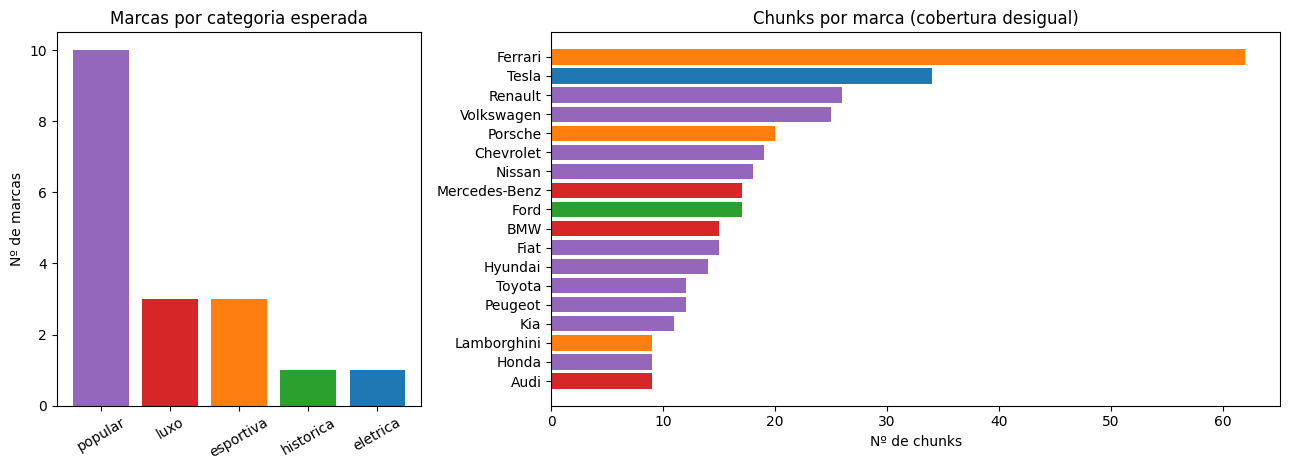

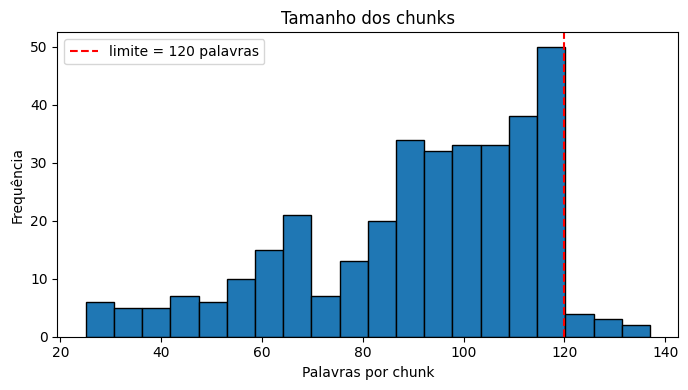

In [19]:
fig = viz.fig_classes(corpus, chunks); viz.salvar(fig, "v1_classes_e_cobertura", cfg.dir_figuras); plt.show()
fig = viz.fig_tamanho_chunks(chunks, cfg.max_palavras_chunk); viz.salvar(fig, "v2_tamanho_chunks", cfg.dir_figuras); plt.show()

**Tokenização, lematização e stopwords (spaCy `pt_core_news_sm` + NLTK, S006–S008).** Reprodução do pipeline do Trabalho 1: descartar espaços, pontuação e stopwords e manter o **lema** (`carros`/`carro`).

*Decisão sobre stopwords.* Na análise de sentimentos (S0016) "não" é decisivo, e removê-lo seria um erro. Na **busca textual** o raciocínio é outro: as stopwords aparecem em quase todos os trechos e quase não discriminam um chunk de outro. Mesmo assim, **não assume** isso: a ablação da Seção 4 compara `tfidf_bruto` (com stopwords, sem lematizar) contra `tfidf_lematizado`.

**Importante:** a pergunta do usuário passa pelo *mesmo* pré-processamento dos chunks, senão os vocabulários não se encontram.

In [20]:
preprocessar = PreprocessadorSimples() if MODO_AMOSTRA else LematizadorSpacy(cfg.modelo_spacy)
chunks["texto_lematizado"] = preprocessar(chunks["texto"])

amostra = chunks.iloc[0]
tokens = preprocessar.tokens(amostra["texto"]) if hasattr(preprocessar, "tokens") else amostra["texto"].split()
print("TOKENS:", tokens[:18])
print("LEMAS :", amostra["texto_lematizado"].split()[:18])

palavras_antes = [p for t in chunks["texto"] for p in re.findall(r"\w+", t.lower())]
palavras_depois = [p for t in chunks["texto_lematizado"] for p in t.split()]
vocab_antes, vocab_depois = len(set(palavras_antes)), len(set(palavras_depois))
print(f"\nANTES : {len(palavras_antes):,} tokens | vocabulário {vocab_antes:,}")
print(f"DEPOIS: {len(palavras_depois):,} tokens | vocabulário {vocab_depois:,} "
      f"(redução de {100 * (1 - vocab_depois / vocab_antes):.1f}% do vocabulário)")

TOKENS: ['Toyota', 'Motor', 'Corporation', 'em', 'Japonês', 'トヨタ自動車株式会社', 'Toyota', 'Jidōsha', 'kabushikigaisha', 'é', 'um', 'fabricante', 'automotivo', 'japonês', 'com', 'sede', 'na', 'cidade']
LEMAS : ['toyota', 'motor', 'corporation', 'japonês', 'トヨタ自動車株式会社', 'toyota', 'jidōsha', 'kabushikigaisha', 'fabricante', 'automotivo', 'japonês', 'sede', 'cidade', 'toyota', 'província', 'aichi', 'japão', 'março']

ANTES : 31,756 tokens | vocabulário 5,966
DEPOIS: 17,684 tokens | vocabulário 4,873 (redução de 18.3% do vocabulário)


**Representação textual.** Cada chunk vira um vetor. Comparamos quatro representações (a ablação da Seção 4 mede o efeito de cada decisão), mais um ranqueamento aleatório como piso de acaso:

| Estratégia | Representação | Papel |
|---|---|---|
| `bow_bruto` | Bag of Words (contagem), texto bruto | **abordagem de referência** (a mais simples) |
| `tfidf_bruto` | TF-IDF, texto bruto | efeito do TF-IDF isolado |
| `tfidf_lematizado` | TF-IDF, lematizado e sem stopwords | pipeline do Trabalho 1 |
| `tfidf_lematizado_bigramas` | idem + bigramas | efeito de n-gramas (S009) |
| `aleatorio` | notas aleatórias | piso de acaso |

O vocabulário e o IDF são aprendidos **somente nos chunks** (`fit`); a pergunta só passa por `transform` — sem vazamento (S0013).

In [21]:
buscadores = {nome: BuscadorLexico(est, preprocessar).ajustar(chunks, chunks["texto_lematizado"])
              for nome, est in estrategias_padrao().items()}
buscadores["aleatorio"] = BuscadorAleatorio(cfg.semente).ajustar(chunks)

principal = buscadores["tfidf_lematizado"]
X = principal.matriz_
esparsidade = 100 * (1 - X.nnz / (X.shape[0] * X.shape[1]))
print(f"Matriz TF-IDF chunks × termos: {X.shape} | esparsidade {esparsidade:.1f}%")

vocab = principal.vetorizador_.get_feature_names_out()
linha = X[0].toarray().ravel(); top = linha.argsort()[::-1][:8]
print(f"\nTermos mais pesados no chunk '{chunks.at[0, 'chunk_id']}':")
display(pd.DataFrame({"termo": vocab[top], "tfidf": linha[top].round(3)}))

Matriz TF-IDF chunks × termos: (344, 4637) | esparsidade 99.1%

Termos mais pesados no chunk 'Toyota_000':


,termo,tfidf
0,toyota,0.504
1,fabricante,0.261
2,mundo,0.226
3,japones,0.222
4,milhao,0.177
5,338,0.157
6,kabushikigaisha,0.157
7,corporacao,0.157


---
## 3. Modelo principal — busca textual por similaridade

A abordagem escolhida é **busca textual / similaridade**: a pergunta é vetorizada no mesmo espaço dos chunks e os chunks são ranqueados pela **similaridade de cosseno**. Não há treino supervisionado; o "modelo" é a representação + a medida de similaridade.

*Por que não classificação ou agrupamento?* O agrupamento já foi explorado no T1 sem sucesso, e a classificação por categoria teria 1 marca em 2 das 5 classes. A busca tem gabarito objetivo (o trecho que contém a resposta) e é a base natural do RAG.

In [22]:
def mostrar_busca(buscador, pergunta, k=3):
    return pd.DataFrame([{"nota": round(r.nota, 3), "marca": r.marca, "trecho": r.texto[:150] + "…"}
                         for r in buscador.buscar(pergunta, k)])

for pergunta in ["Quem fundou a Ferrari?", "Qual montadora japonesa lançou o Prius?"]:
    print("\n>>", pergunta)
    display(mostrar_busca(principal, pergunta))


>> Quem fundou a Ferrari?


,nota,marca,trecho
0,0.246,Ferrari,"A partir da década de 2010, a Ferrari passou a depender cada vez mais do design interno do Centro Stile Fe..."
1,0.238,Ferrari,"A Ferrari também forneceu um motor V8 para o carro “Powered by Ferrari”, utilizado na série A1 Grand Prix ..."
2,0.220,Ferrari,"Enzo Ferrari, anteriormente vendedor e piloto de corrida da Alfa Romeo, fundou em 1929 a Scuderia Ferrari,..."



>> Qual montadora japonesa lançou o Prius?


,nota,marca,trecho
0,0.291,Nissan,Atualmente a Nissan possui plantas de montagem nos respectivos países (algumas em coprodução com a Renault...
1,0.130,Renault,"O Grupo Renault é formado atualmente por 6 marcas automotivas, sendo elas a Renault, principal marca do gr..."
2,0.124,Chevrolet,"Em setembro de 2011, a Chevrolet lançou o Cruze, no Brasil, com o motor Ecotec 6 e transmissão automática ..."


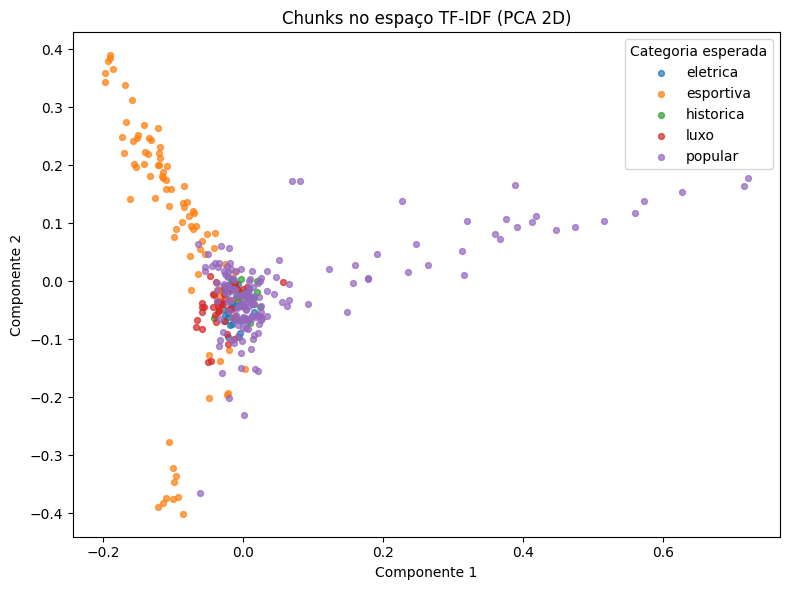

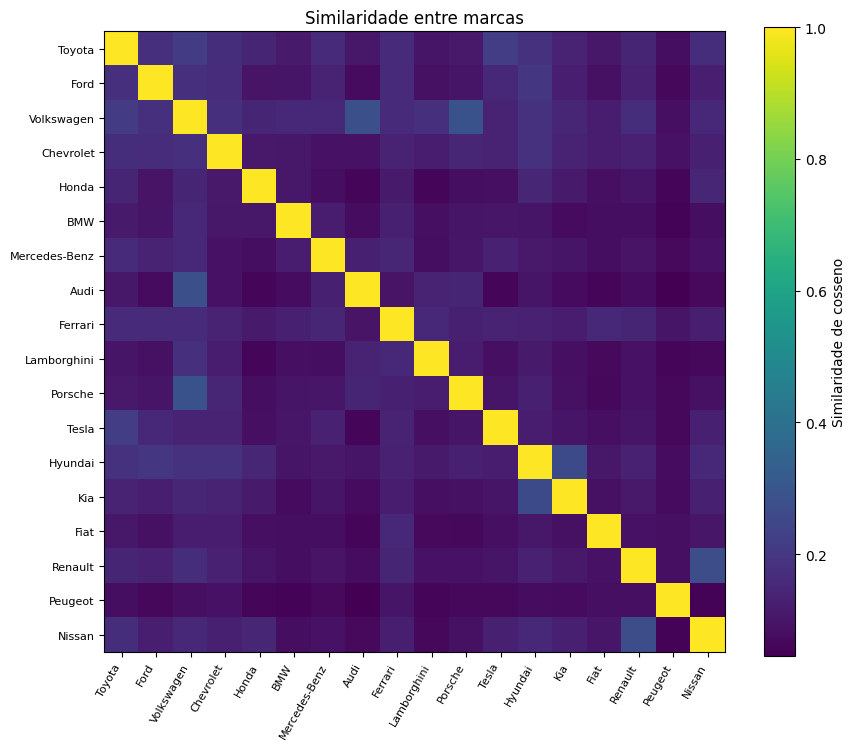

similaridade
Volkswagen Porsche         0.284
           Audi            0.277
Renault    Nissan          0.269
Hyundai    Kia             0.260
Toyota     Tesla           0.219

In [23]:
fig = viz.fig_lsa_chunks(principal.matriz_, chunks, cfg.semente); viz.salvar(fig, "v3_lsa_chunks", cfg.dir_figuras); plt.show()

sim = similaridade_entre_marcas(principal)
fig = viz.fig_similaridade_marcas(sim); viz.salvar(fig, "v4_similaridade_marcas", cfg.dir_figuras); plt.show()

triangulo = sim.where(np.triu(np.ones(sim.shape, dtype=bool), k=1)).stack().dropna()
display(triangulo.sort_values(ascending=False).head(5).round(3).to_frame("similaridade"))

---
## 4. Avaliação

**Gold set** (`data/gold_perguntas.csv`): 36 perguntas com resposta (2 por marca: *explícita*, que cita a marca, e *implícita*, que só descreve) e 8 **sem resposta no corpus** (incl. 2 sobre carros em geral). Cada pergunta traz termos de **evidência**; um chunk é *relevante* se for da marca esperada **e** contiver a evidência. Isso mede a recuperação no nível do trecho, não só da marca.

**Protocolo:** metade das perguntas é *dev* (escolher estratégia e calibrar o limiar) e metade é *teste* (relatar). Nada do teste é usado para decisões.

**Métricas:** Hit@k (acertou um trecho relevante entre os k primeiros), MRR (posição do primeiro relevante), acurácia de marca no top-1, matriz de confusão e intervalo de confiança por *bootstrap* (a amostra é pequena).

In [24]:
bruto = validar_gold(gold_amostra() if MODO_AMOSTRA else carregar_gold(DIR_DADOS / "gold_perguntas.csv"), chunks)
print(f"Perguntas válidas (evidência encontrada no corpus): {int(bruto['valida'].sum())}/{len(bruto)}")
invalidas = bruto[~bruto["valida"]]
if len(invalidas):
    print("\nATENÇÃO — perguntas sem evidência no corpus (ficam fora da avaliação; ajuste a coluna 'evidencias'):")
    display(invalidas[["id", "pergunta", "marca_esperada", "evidencias"]])

gold = bruto[bruto["valida"]]
dev = gold[gold["particao"] == "dev"].reset_index(drop=True)
teste = gold[gold["particao"] == "teste"].reset_index(drop=True)
display(gold.groupby(["particao", "tipo"]).size().unstack(fill_value=0))

Perguntas válidas (evidência encontrada no corpus): 41/44

ATENÇÃO — perguntas sem evidência no corpus (ficam fora da avaliação; ajuste a coluna 'evidencias'):


,id,pergunta,marca_esperada,evidencias
10,Q11,Em que cidade fica a sede da BMW?,BMW,munique|munich
14,Q15,Onde fica a sede da Audi?,Audi,ingolstadt
15,Q16,Qual marca alemã usa quatro anéis entrelaçados como logotipo?,Audi,aneis


tipo,explicita,implicita,sem_resposta
particao,,,
dev,9,8,4
teste,7,9,4


In [25]:
def tabela_metricas(particao):
    return pd.DataFrame({nome: resumir_metricas(metricas_busca(b.notas(particao["pergunta"]), particao, chunks))
                         for nome, b in buscadores.items()}).T

tabela_dev = tabela_metricas(dev)
print("DEV — usado só para escolher a estratégia:")
display(tabela_dev.round(3))

PRIORIDADE = ["tfidf_lematizado", "tfidf_lematizado_bigramas", "tfidf_bruto", "bow_bruto"]
candidatas = tabela_dev.drop(index="aleatorio")
escolhido = max(candidatas.index, key=lambda n: (candidatas.at[n, "MRR"], candidatas.at[n, "hit@1"], -PRIORIDADE.index(n)))
buscador = buscadores[escolhido]
print("Estratégia escolhida no dev:", escolhido)

DEV — usado só para escolher a estratégia:


,hit@1,hit@3,hit@5,MRR,acc_marca_top1,n_perguntas
bow_bruto,0.353,0.647,0.706,0.504,0.765,17.0
tfidf_bruto,0.353,0.765,0.765,0.566,0.706,17.0
tfidf_lematizado,0.353,0.706,0.941,0.576,0.824,17.0
tfidf_lematizado_bigramas,0.294,0.706,0.941,0.517,0.765,17.0
aleatorio,0.059,0.059,0.059,0.087,0.118,17.0


Estratégia escolhida no dev: tfidf_lematizado


TESTE — resultado a relatar:


,hit@1,hit@3,hit@5,MRR,acc_marca_top1,n_perguntas
bow_bruto,0.250,0.500,0.500,0.404,0.625,16.0
tfidf_bruto,0.438,0.625,0.812,0.591,0.688,16.0
tfidf_lematizado,0.438,0.625,0.875,0.604,0.688,16.0
tfidf_lematizado_bigramas,0.375,0.688,0.875,0.571,0.625,16.0
aleatorio,0.000,0.062,0.062,0.062,0.000,16.0


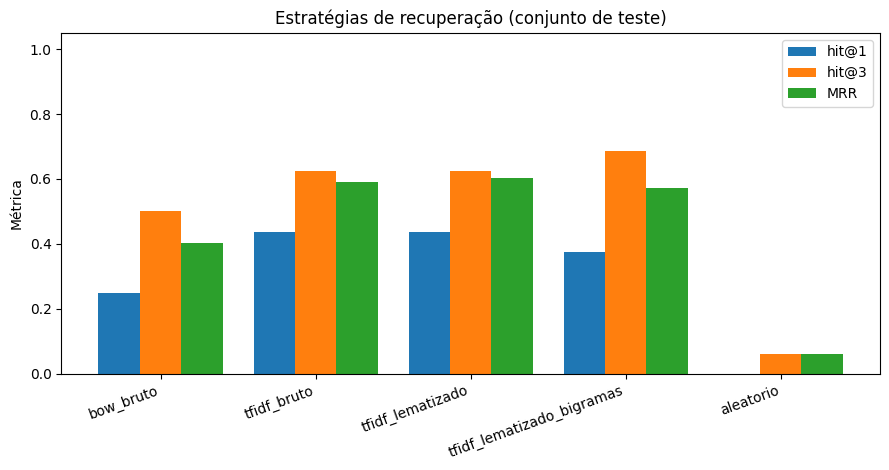

,estrategia,hit@1,IC95% hit@1,MRR,IC95% MRR
0,tfidf_lematizado,0.438,[0.19; 0.69],0.604,[0.43; 0.79]
1,bow_bruto,0.250,[0.06; 0.50],0.404,[0.23; 0.60]


Por tipo de pergunta (estratégia escolhida):


,hit@1,hit@3,reciproco
tipo,,,
explicita,0.286,0.429,0.460
implicita,0.556,0.778,0.717


In [26]:
tabela_teste = tabela_metricas(teste)
print("TESTE — resultado a relatar:")
display(tabela_teste.round(3))

fig = viz.fig_comparacao_estrategias(tabela_teste); viz.salvar(fig, "v5_comparacao_estrategias", cfg.dir_figuras); plt.show()

REFERENCIA = "bow_bruto"
det_teste = metricas_busca(buscador.notas(teste["pergunta"]), teste, chunks)
det_ref = metricas_busca(buscadores[REFERENCIA].notas(teste["pergunta"]), teste, chunks)

def linha_ic(nome, det):
    h, m = ic_bootstrap(det["hit@1"].astype(float)), ic_bootstrap(det["reciproco"])
    return {"estrategia": nome, "hit@1": round(det["hit@1"].mean(), 3), "IC95% hit@1": f"[{h[0]:.2f}; {h[1]:.2f}]",
            "MRR": round(det["reciproco"].mean(), 3), "IC95% MRR": f"[{m[0]:.2f}; {m[1]:.2f}]"}

tabela_ic = pd.DataFrame([linha_ic(escolhido, det_teste), linha_ic(REFERENCIA, det_ref)])
display(tabela_ic)
print("Por tipo de pergunta (estratégia escolhida):")
display(det_teste.groupby("tipo")[["hit@1", "hit@3", "reciproco"]].mean().round(3))

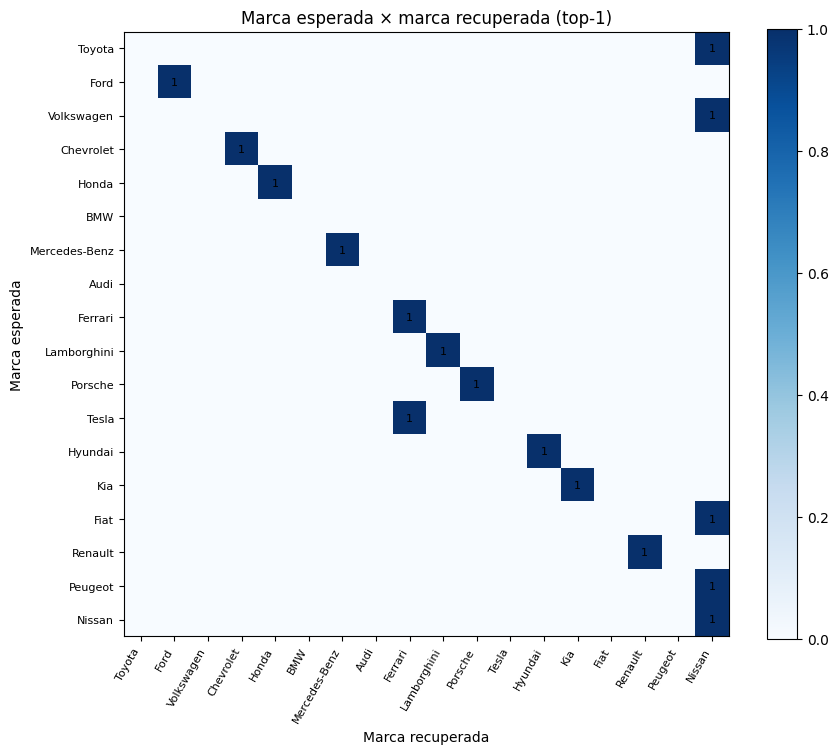

Falhas em top-1: 9 de 16 perguntas do teste


,quantidade
tipo_erro,
marca errada,5
"marca certa, trecho sem a evidência",4


,id,pergunta,tipo,marca_esperada,marca_top1,nota_top1,posicao_primeiro_relevante,tipo_erro,trecho_recuperado
0,Q02,Qual montadora japonesa lançou o Prius?,implicita,Toyota,Nissan,0.291333,4,marca errada,Atualmente a Nissan possui plantas de montagem nos respectivos países (algumas em coprodução com a Renault...
1,Q03,Qual carro da Ford popularizou a produção em massa?,explicita,Ford,Ford,0.317526,5,"marca certa, trecho sem a evidência",O conceito de carro global atualmente é uma coisa necessária em função de redução de custos de produção e ...
2,Q06,Qual montadora alemã produziu o Fusca?,implicita,Volkswagen,Nissan,0.383290,5,marca errada,Atualmente a Nissan possui plantas de montagem nos respectivos países (algumas em coprodução com a Renault...
7,Q19,Quem fundou a Lamborghini?,explicita,Lamborghini,Lamborghini,0.338706,7,"marca certa, trecho sem a evidência","Entretanto, em 1968 tinha sido apresentado o Lamborghini Islero, destinado a substituir o 400 GT, que havi..."
9,Q23,Quem é o presidente executivo da Tesla?,explicita,Tesla,Ferrari,0.325606,2,marca errada,"Após a renúncia de Montezemolo, vários presidentes e diretores-executivos sucederam-se rapidamente. Seu pr..."
11,Q27,Em que ano a Kia foi fundada?,explicita,Kia,Kia,0.692770,4,"marca certa, trecho sem a evidência",Kia Spectra Kia Cerato Kia K3 Kia Cee'd Kia Rio Kia Picanto Kia Stonic Kia Soul Kia Venga Kia Magentis Kia...
12,Q30,Qual montadora italiana fabricou o Uno e o Palio?,implicita,Fiat,Nissan,0.264278,2,marca errada,Atualmente a Nissan possui plantas de montagem nos respectivos países (algumas em coprodução com a Renault...
14,Q34,Qual montadora francesa integra o grupo Stellantis e produz o modelo 208?,implicita,Peugeot,Nissan,0.249563,2,marca errada,Atualmente a Nissan possui plantas de montagem nos respectivos países (algumas em coprodução com a Renault...
15,Q35,Em que cidade japonesa fica a sede da Nissan?,explicita,Nissan,Nissan,0.372967,8,"marca certa, trecho sem a evidência","A Nissan (japonês: 日産自動車株式会社, Hepburn: Nissan Jidōsha Kabushiki-gaisha) é uma fabricante japonesa de autom..."


In [27]:
cm = tabela_confusao_marcas(det_teste, list(corpus["marca"]))
fig = viz.fig_matriz_confusao(cm); viz.salvar(fig, "v6_matriz_confusao", cfg.dir_figuras); plt.show()

erros = analisar_erros(det_teste, chunks)
print(f"Falhas em top-1: {len(erros)} de {len(det_teste)} perguntas do teste")
if len(erros):
    display(erros["tipo_erro"].value_counts().to_frame("quantidade"))
    display(erros)

### Abstenção: o que fazer quando o corpus não tem a resposta?

A recuperação sempre devolve *algum* trecho, mesmo para "Qual a capital da Austrália?". Usamos a **nota do top-1** como sinal: abaixo de um **limiar** o sistema se abstém e o LLM nem é chamado. O limiar é calibrado **só no dev** (acurácia balanceada) e avaliado no teste.

Limiar (calibrado no dev): 0.2208
Teste: {'limiar': 0.221, 'respondidas_com_resposta': 0.938, 'abstencoes_corretas_sem_resposta': 1.0, 'acuracia_balanceada': 0.969}


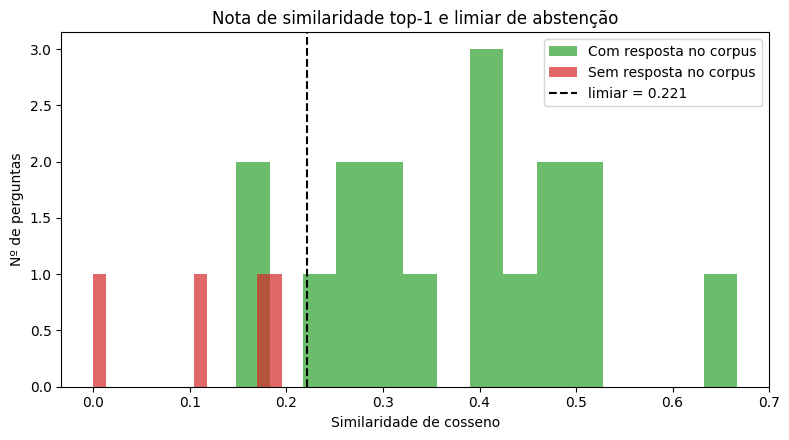

In [28]:
def nota_top1(b, particao):
    return b.notas(particao["pergunta"]).max(axis=1)

com_dev = (dev["tipo"] != "sem_resposta").to_numpy()
t_dev = nota_top1(buscador, dev)
limiar = escolher_limiar(t_dev[com_dev], t_dev[~com_dev])
abstencao_teste = avaliar_abstencao(nota_top1(buscador, teste), teste["tipo"], limiar)
print("Limiar (calibrado no dev):", round(limiar, 4))
print("Teste:", {k: round(v, 3) for k, v in abstencao_teste.items()})

fig = viz.fig_distribuicao_notas(t_dev[com_dev], t_dev[~com_dev], limiar); viz.salvar(fig, "v7_notas_e_limiar", cfg.dir_figuras); plt.show()

---
## 5. Componente contemporâneo — RAG com modelo pré-treinado (Hugging Face)

Só **depois** de a recuperação tradicional ter sido construída e avaliada entra o modelo de linguagem: **`google/flan-t5-small`** via `pipeline("text2text-generation")`, **somente inferência** (nenhum peso é alterado).

Fluxo: pergunta → busca TF-IDF/cosseno → **limiar** → prompt `Contexto + Pergunta + "Responda com base no contexto."` (formato da aula S017) → FLAN-T5. A resposta sempre acompanha **marca, nota, URL e trecho de evidência**, então pode ser auditada.

**O LLM não substitui as etapas tradicionais:** a escolha do trecho, a decisão de abstenção e toda a avaliação da Seção 4 independem dele.

> Limitação conhecida: o FLAN-T5-small é compacto e tem desempenho limitado em português. Por isso medimos separadamente a **recuperação** e a **geração**.

In [29]:
gerador = GeradorEco() if MODO_AMOSTRA else GeradorFlanT5(cfg.modelo_llm)
assistente = AssistenteRAG(buscador, gerador, limiar, preprocessar,
                           n_trechos=cfg.n_trechos_contexto, limite_tokens=cfg.max_tokens_resposta)

for pergunta in ["Quem fundou a Ferrari?", "Qual é a capital da Austrália?"]:
    r = assistente.responder(pergunta)
    print(f"\n>> {pergunta}\n   resposta  : {r.resposta}\n   abstenção : {r.abstencao} | marca: {r.marca} | nota: {r.nota:.3f} | fidelidade: {r.fidelidade:.2f}\n   fonte     : {r.fonte}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/308M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Device set to use cpu



>> Quem fundou a Ferrari?
   resposta  : A partir de decada de 2010, a Ferrari passou a depender cada vez mais do design interno do Centro Stile Ferrari para o estilo de se su automoveis de rua, embora tenha mantido colaboracoes ocasionais em projetos limitados.
   abstenção : False | marca: Ferrari | nota: 0.246 | fidelidade: 0.89
   fonte     : https://pt.wikipedia.org/wiki/Ferrari

>> Qual é a capital da Austrália?
   resposta  : Não há informação suficiente no corpus para responder.
   abstenção : True | marca: Chevrolet | nota: 0.113 | fidelidade: 0.00
   fonte     : https://pt.wikipedia.org/wiki/Chevrolet


### Formato do prompt (escolha no dev)
A aula S017 sugere repetir a mesma pergunta com instruções diferentes. Comparamos três formatos **só no dev** e usamos o melhor no teste: `pt_curto` (o da aula), `en_curto` (instrução em inglês, idioma em que o FLAN-T5 foi mais ajustado) e `pergunta_primeiro`. O acerto só conta se a resposta citar a marca esperada ou um termo de evidência que **não** estava na pergunta (repetir a pergunta não vale).

In [30]:
def acerto_geracao(assistente_, particao):
    resultados = []
    for g in particao[particao["tipo"] != "sem_resposta"].itertuples(index=False):
        r = assistente_.responder(g.pergunta)
        resultados.append(acertou_resposta(r.resposta, g.evidencias, g.pergunta, g.marca_esperada) and not r.abstencao)
    return float(np.mean(resultados)) if resultados else float("nan")

tabela_prompts = {}
for estilo in ESTILOS_PROMPT:
    a = AssistenteRAG(buscador, gerador, limiar, preprocessar, n_trechos=cfg.n_trechos_contexto,
                      limite_tokens=cfg.max_tokens_resposta, estilo_prompt=estilo)
    tabela_prompts[estilo] = acerto_geracao(a, dev)
display(pd.Series(tabela_prompts, name="acerto no dev").round(3).to_frame())

estilo_escolhido = max(ESTILOS_PROMPT, key=lambda e: (tabela_prompts[e], -ESTILOS_PROMPT.index(e)))
print("Formato de prompt escolhido no dev:", estilo_escolhido)

,acerto no dev
pt_curto,0.235
en_curto,0.294
pergunta_primeiro,0.353


Formato de prompt escolhido no dev: pergunta_primeiro


In [31]:
assistente = AssistenteRAG(buscador, gerador, limiar, preprocessar, n_trechos=cfg.n_trechos_contexto,
                           limite_tokens=cfg.max_tokens_resposta, estilo_prompt=estilo_escolhido)
linhas = []
for g in teste.itertuples(index=False):
    com_resposta = g.tipo != "sem_resposta"
    rag = assistente.responder(g.pergunta)
    sem_rag = assistente.responder_sem_rag(g.pergunta)
    linhas.append({
        "id": g.id, "tipo": g.tipo, "pergunta": g.pergunta, "marca_esperada": g.marca_esperada,
        "marca_recuperada": rag.marca, "nota": round(rag.nota, 3), "trecho": rag.trecho[:180] + "…",
        "resposta_sem_rag": sem_rag, "resposta_rag": rag.resposta, "abstencao": rag.abstencao,
        "fidelidade": round(rag.fidelidade, 2),
        "evidencia_no_trecho": contem_evidencia(rag.trecho, g.evidencias) if com_resposta else None,
        "acerto_rag": (acertou_resposta(rag.resposta, g.evidencias, g.pergunta, g.marca_esperada)
                       and not rag.abstencao) if com_resposta else None,
        "acerto_sem_rag": acertou_resposta(sem_rag, g.evidencias, g.pergunta, g.marca_esperada) if com_resposta else None,
        "sustentada_no_corpus (manual)": "",
    })
comparacao = pd.DataFrame(linhas)
display(comparacao[["tipo", "pergunta", "marca_recuperada", "nota", "resposta_sem_rag", "resposta_rag", "abstencao", "fidelidade"]])

,tipo,pergunta,marca_recuperada,nota,resposta_sem_rag,resposta_rag,abstencao,fidelidade
0,implicita,Qual montadora japonesa lançou o Prius?,Nissan,0.291,Pergunta: Qual montadora japonesa lancou o Prius? Responda em uma frase.,"Japao (13 montadoras), India (1 montadora), Brasil (2 montadoras), Indonesia (1 montadora), Malasia (2 mon...",False,1.00
1,explicita,Qual carro da Ford popularizou a produção em massa?,Ford,0.318,Pergunta: Qual carro da Ford popularizou a producao em massa? Responda em uma frase.,"O Ford Fiesta. Carro elaborado com base no conceito Verve e o novo projeto global da marca, a Ford disse r...",False,0.94
2,implicita,Qual montadora alemã produziu o Fusca?,Nissan,0.383,Pergunta: Qual montadora alema produziu o Fusca? Responda em uma frase.,"Japao (13 montadoras), India (1 montadora), Brasil (2 montadoras), Indonesia (1 montadora), Malasia (2 mon...",False,1.00
3,explicita,Quem foi o fundador da Chevrolet?,Chevrolet,0.290,Is it a fundador da Chevrolet? Responda em uma frase.,"Louis Chevrolet co-fundou a Chevrolet Motor Car Company, com William C. Durant (fundador da General Motors...",False,0.96
4,implicita,Qual fabricante japonesa produz o Civic e o Accord?,Honda,0.391,Pergunta: Qual fabricante japonesa produzo o Civic e o Accord? Responda em uma frase.,Honda,False,1.00
5,implicita,Qual marca alemã surgiu das empresas de Karl Benz e Gottlieb Daimler?,Mercedes-Benz,0.425,Pergunta: What marca alema surgiu das empresas de Karl Benz e Gottlieb Daimler? Responda em uma frase.,Mercedes-Benz,False,1.00
6,implicita,Qual fabricante italiana de superesportivos tem sede em Maranello?,Ferrari,0.225,Pergunta: Qual fabricante italiana de superesportivos tem sede em Maranello? Responda em uma frase.,Ferrari,False,1.00
7,explicita,Quem fundou a Lamborghini?,Lamborghini,0.339,Pergunta: What is Lamborghini? Responda em uma frase.,"Lamborghini Islero, destinado a substituir o 400 GT, que havia surgido como desenvolvimento do 350 GT",False,0.90
8,implicita,Qual fabricante alemã de esportivos produz o utilitário Cayenne?,Porsche,0.191,Pergunta: Qual fabricante alema de esportivos produz o utilitario Cayenne? Responda em uma frase.,Não há informação suficiente no corpus para responder.,True,0.00
9,explicita,Quem é o presidente executivo da Tesla?,Ferrari,0.326,Pergunta: Who is the executivo of Tesla? Responda em uma frase.,"a renuncia de Montezemolo, varios presidentes e diretores-executivos sucederam-se rapidamente",False,0.88


In [32]:
resp = comparacao[comparacao["tipo"] != "sem_resposta"]
sem = comparacao[comparacao["tipo"] == "sem_resposta"]
respondidas = resp[~resp["abstencao"]]

resumo_rag = {
    "trecho recuperado contém a evidência": resp["evidencia_no_trecho"].astype(float).mean(),
    "resposta COM RAG acerta": resp["acerto_rag"].astype(float).mean(),
    "resposta SEM RAG acerta": resp["acerto_sem_rag"].astype(float).mean(),
    "fidelidade média ao contexto (COM RAG)": respondidas["fidelidade"].mean() if len(respondidas) else float("nan"),
    "abstenção correta (sem resposta no corpus)": sem["abstencao"].astype(float).mean(),
    "abstenção indevida (com resposta no corpus)": resp["abstencao"].astype(float).mean(),
}
display(pd.Series(resumo_rag).round(3).to_frame("valor"))

falha_recuperacao = resp[~resp["evidencia_no_trecho"].astype(bool)]
falha_geracao = resp[resp["evidencia_no_trecho"].astype(bool) & ~resp["acerto_rag"].astype(bool)]
print(f"Falhas de RECUPERAÇÃO (trecho sem a evidência): {len(falha_recuperacao)}")
print(f"Falhas de GERAÇÃO (trecho certo, resposta errada): {len(falha_geracao)}")
display(falha_geracao[["pergunta", "resposta_rag", "fidelidade"]])

,valor
trecho recuperado contém a evidência,0.438
resposta COM RAG acerta,0.312
resposta SEM RAG acerta,0.000
fidelidade média ao contexto (COM RAG),0.974
abstenção correta (sem resposta no corpus),1.000
abstenção indevida (com resposta no corpus),0.062


Falhas de RECUPERAÇÃO (trecho sem a evidência): 9
Falhas de GERAÇÃO (trecho certo, resposta errada): 2


,pergunta,resposta_rag,fidelidade
8,Qual fabricante alemã de esportivos produz o utilitário Cayenne?,Não há informação suficiente no corpus para responder.,0.0
13,Quem fundou a Renault?,"Renault Twingo III (2014), 'City' Carro do Ano na UK 2015 Renault Clio IV (2012) Renault Sandero II (2012)...",1.0


In [33]:
try:
    import gradio as gr

    def _responder(pergunta):
        r = assistente.responder(pergunta)
        return r.resposta, f"{r.marca} (nota {r.nota:.3f})\n{r.fonte}\n\n{r.trecho}"

    demo = gr.Interface(fn=_responder, inputs=gr.Textbox(label="Pergunta"),
                        outputs=[gr.Textbox(label="Resposta"), gr.Textbox(label="Evidência recuperada")],
                        title="Assistente de marcas de carros (RAG)")
except ImportError:
    print("Gradio não instalado — célula opcional.")

---
## 6. Exportação dos resultados
Gera `resultados/` com tabelas e um `resumo_resultados.md` com todos os números usados no relatório e nos slides.

In [34]:
saida = cfg.dir_resultados
tabela_dev.round(4).to_csv(saida / "metricas_dev.csv")
tabela_teste.round(4).to_csv(saida / "metricas_teste.csv")
tabela_ic.to_csv(saida / "metricas_teste_ic.csv", index=False)
comparacao.to_csv(saida / "comparacao_rag.csv", index=False)
if len(erros):
    erros.to_csv(saida / "analise_erros.csv", index=False)

resumo = f"""# Resumo dos resultados (gerado pelo notebook)

## Corpus e processamento
- Documentos: {len(corpus)} marcas | palavras brutas: {int(corpus['n_palavras_bruto'].sum()):,}
- Categorias: {corpus['categoria_esperada'].value_counts().to_dict()}
- Chunks: {len(chunks)} (mediana {chunks['n_palavras'].median():.0f} palavras)
- Tokens: {len(palavras_antes):,} -> {len(palavras_depois):,} | vocabulário: {vocab_antes:,} -> {vocab_depois:,}
- Matriz TF-IDF: {X.shape} | esparsidade {esparsidade:.1f}%

## Avaliação da recuperação
- Perguntas válidas: {int(bruto['valida'].sum())}/{len(bruto)} | dev: {len(dev)} | teste: {len(teste)}
- Estratégia escolhida no dev: {escolhido} | referência: {REFERENCIA}

Teste:
{tabela_teste.round(3).to_string()}

IC 95% (bootstrap):
{tabela_ic.to_string(index=False)}

- Falhas em top-1 no teste: {len(erros)} de {len(det_teste)}

## Abstenção
- Limiar (dev): {limiar:.4f}
- Teste: { {k: round(v, 3) for k, v in abstencao_teste.items()} }

## RAG (FLAN-T5-small)
- Formato de prompt escolhido no dev: {estilo_escolhido} | acerto no dev: { {k: round(v, 3) for k, v in tabela_prompts.items()} }
{pd.Series(resumo_rag).round(3).to_string()}
- Falhas de recuperação: {len(falha_recuperacao)} | falhas de geração: {len(falha_geracao)}
"""
(saida / "resumo_resultados.md").write_text(resumo, encoding="utf-8")
print(resumo)

# Resumo dos resultados (gerado pelo notebook)

## Corpus e processamento
- Documentos: 18 marcas | palavras brutas: 32,469
- Categorias: {'popular': 10, 'luxo': 3, 'esportiva': 3, 'historica': 1, 'eletrica': 1}
- Chunks: 344 (mediana 96 palavras)
- Tokens: 31,756 -> 17,684 | vocabulário: 5,966 -> 4,873
- Matriz TF-IDF: (344, 4637) | esparsidade 99.1%

## Avaliação da recuperação
- Perguntas válidas: 41/44 | dev: 21 | teste: 20
- Estratégia escolhida no dev: tfidf_lematizado | referência: bow_bruto

Teste:
                           hit@1  hit@3  hit@5    MRR  acc_marca_top1  n_perguntas
bow_bruto                  0.250  0.500  0.500  0.404           0.625         16.0
tfidf_bruto                0.438  0.625  0.812  0.591           0.688         16.0
tfidf_lematizado           0.438  0.625  0.875  0.604           0.688         16.0
tfidf_lematizado_bigramas  0.375  0.688  0.875  0.571           0.625         16.0
aleatorio                  0.000  0.062  0.062  0.062           0.000    

---
## 7. Conclusões e limitações

**Conclusões**:
1. A recuperação TF-IDF + cosseno supera a linha de base de acaso por larga margem; o ganho sobre o BoW bruto mostra o efeito da lematização/stopwords.
2. Perguntas *implícitas* (sem citar a marca) são mais difíceis que as *explícitas* — a busca é lexical, não semântica.
3. O limiar de abstenção separa razoavelmente as perguntas sem resposta, mas perguntas sobre *carros em geral* ("óleo do motor") são o caso mais difícil.
4. O RAG ancora a resposta no trecho e permite auditá-la; porém o FLAN-T5-small é fraco em português — separar falhas de recuperação e de geração mostra onde melhorar.

**Limitações:** busca puramente lexical (sinônimos e paráfrases escapam); gold set pequeno e autoral (por isso os intervalos de confiança são largos); fonte única; LLM pequeno; heurística de "evidência na resposta" não prova correção factual.